## Feature Extraction Anatomica con Nilearn

### Estrazione delle metriche volumetriche delle Regioni di Interesse (ROI) dalle scansioni 3D MNI152 usando l'atlante anatomico Harvard-Oxford per integrarle nei modelli di Machine Learning

Dataset tabellare caricato: 436 soggetti
Download dell'atlante Harvard-Oxford...
[fetch_atlas_harvard_oxford] Dataset directory found: C:\Users\filip\nilearn_data\fsl
Indice Left Hippocampus: 9 (Left Hippocampus)
Indice Right Hippocampus: 19 (Right Hippocampus)


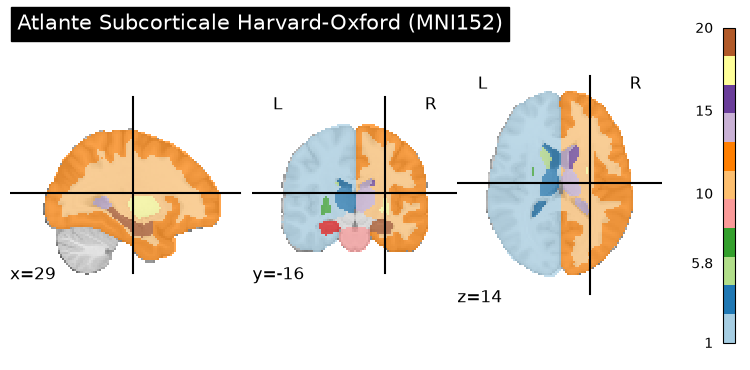

In [4]:
import os
import pandas as pd
import numpy as np
import nibabel as nib
from nilearn import datasets, image, plotting

# 1. Caricamento del dataset tabellare OASIS-1
csv_path = "C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data/raw/oasis_cross-sectional-5708aa0a98d82080.csv"
df = pd.read_csv(csv_path)
print(f"Dataset tabellare caricato: {df.shape[0]} soggetti")

# 2. Download dell'atlante corticale e subcorticale Harvard-Oxford
print("Download dell'atlante Harvard-Oxford...")
atlas_sub = datasets.fetch_atlas_harvard_oxford('sub-maxprob-thr25-2mm')
atlas_filename = atlas_sub.maps
labels = atlas_sub.labels

# 3. Identifichiamo gli indici dell'Ippocampo (Left & Right Hippocampus)
left_hippo_idx = [i for i, label in enumerate(labels) if 'Left Hippocampus' in label][0]
right_hippo_idx = [i for i, label in enumerate(labels) if 'Right Hippocampus' in label][0]
print(f"Indice Left Hippocampus: {left_hippo_idx} ({labels[left_hippo_idx]})")
print(f"Indice Right Hippocampus: {right_hippo_idx} ({labels[right_hippo_idx]})")

# 4. Visualizziamo l'atlante per verificare la maschera subcorticale
plotting.plot_roi(
    atlas_filename,
    title="Atlante Subcorticale Harvard-Oxford (MNI152)",
    display_mode="ortho",
    cmap="Paired"
)
plotting.show()

### Estrazione del volume dell'Ippocampo per il soggetto di test

File trovato automaticamente: C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data\raw\disc1\OAS1_0001_MR1\RAW\OAS1_0001_MR1_mpr-1_anon.img


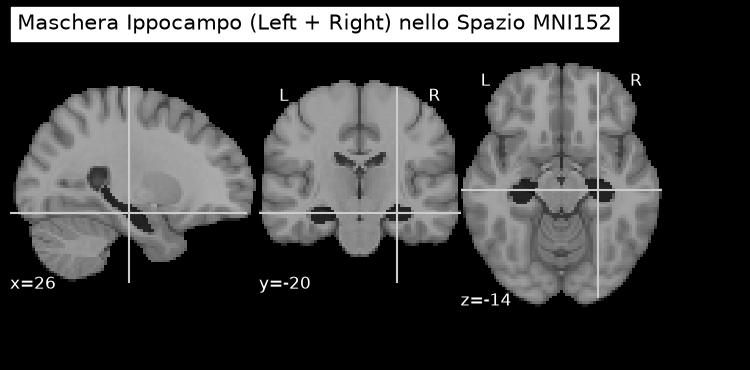

In [5]:
# 1. Definiamo il percorso al primo file MRI (OAS1_0001_MR1)
# Verificale e adatta la cartella data se necessario
data_dir = "C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data" 
target_file = os.path.join(data_dir, "OAS1_0001_MR1", "RAW", "OAS1_0001_MR1_mpr-1_anon.img")

# Se il file .img/.hdr non esiste in quel percorso, cerchiamo il primo disponibile
if not os.path.exists(target_file):
    import glob
    img_files = glob.glob(f"{data_dir}/**/RAW/*.img", recursive=True)
    if img_files:
        target_file = img_files[0]
        print(f"File trovato automaticamente: {target_file}")
    else:
        raise FileNotFoundError("Nessun file .img trovato nella cartella data!")

# 2. Carichiamo la mappa dell'atlante come oggetto NIfTI
atlas_img = image.load_img(atlas_filename)
atlas_data = atlas_img.get_fdata()

# 3. Creiamo una maschera booleana che isola solo l'Ippocampo (Sinistro + Destro)
hippo_mask_data = (atlas_data == left_hippo_idx) | (atlas_data == right_hippo_idx)
hippo_mask_img = nib.Nifti1Image(hippo_mask_data.astype(np.int32), affine=atlas_img.affine)

# 4. Visualizziamo la maschera dell'Ippocampo sovrapposta al template MNI152
mni_template = datasets.load_mni152_template(resolution=2)
plotting.plot_roi(
    hippo_mask_img,
    bg_img=mni_template,
    title="Maschera Ippocampo (Left + Right) nello Spazio MNI152",
    display_mode="ortho",
    cmap="gist_heat"
)
plotting.show()

In [6]:
# 5. Calcoliamo il volume dell'ippocampo in mm^3 per OAS1_0001_MR1
img_nib = nib.load(target_file)
img_canonical = nib.as_closest_canonical(img_nib)

img_resampled = image.resample_to_img(
    source_img=img_canonical,
    target_img=atlas_img
)

# Estraiamo i voxel all'interno della maschera dell'ippocampo
mri_data_resampled = img_resampled.get_fdata()
voxel_volume = np.abs(np.linalg.det(atlas_img.affine[:3, :3])) # Volume voxel in mm^3

# Calcoliamo il volume approssimativo della materia cerebrale nell'ippocampo
# consideriamo i voxel con intensità > 0 all'interno della maschera
hippo_voxels = mri_data_resampled[hippo_mask_data]
hippo_volume_mm3 = np.sum(hippo_voxels > 0) * voxel_volume

print(f"Volume calcolato dell'Ippocampo per OAS1_0001_MR1: {hippo_volume_mm3:.2f} mm³")

C:\Users\filip\AppData\Local\Temp\ipykernel_7600\3815894523.py:5: UserWarning: Casting data from int16 to float32
  img_resampled = image.resample_to_img(


Volume calcolato dell'Ippocampo per OAS1_0001_MR1: 11112.00 mm³


### Loop di estrazione automatica per tutti i soggetti

In [7]:
import glob
from tqdm import tqdm

def extract_hippocampus_volumes(data_directory, atlas_image, left_idx, right_idx):
    """
    Scorre tutte le scansioni nel dataset, registra su MNI ed estrae i volumi ippocampali 
    applicando una soglia d'intensità per isolare la sola materia grigia.
    """
    # Troviamo tutti i file .img nelle sottocartelle RAW
    search_pattern = os.path.join(data_directory, "**", "RAW", "*.img")
    subject_files = sorted(glob.glob(search_pattern, recursive=True))

    print(f"Trovate {len(subject_files)} scansioni 3D nel dataset.")

    # Prepariamo la maschera anatomica
    atlas_data = atlas_image.get_fdata()
    left_mask = (atlas_data == left_idx)
    right_mask = (atlas_data == right_idx)

    voxel_vol = np.abs(np.linalg.det(atlas_image.affine[:3, :3]))
    results = []

    for file_path in tqdm(subject_files, desc="Estrazione Feature ROI"):
        # Estraiamo l'ID del soggetto dal percorso (es. OAS1_0001_MR1)
        subject_id = os.path.basename(file_path).split('_mpr')[0]

        try:
            # Caricamento e allineamento canonico
            img_nib = nib.load(file_path)
            img_canonical = nib.as_closest_canonical(img_nib)

            # Ricampionamento sullo spazio dell'atlante
            img_resample = image.resample_to_img(
                source_img=img_canonical,
                target_img=atlas_image
            )

            mri_data = img_resample.get_fdata()
            if mri_data.ndim == 4:
                mri_data = mri_data[:, :, :, 0]

            # Calcolo soglia dinamica sul segnale cerebrale per escludere sfondi/liquidi
            nonzero_voxels = mri_data[mri_data > 0]
            if len(nonzero_voxels) > 0:
                intensity_threshold = np.percentile(nonzero_voxels, 35) # Soglia per isolare la materia grigia
            else:
                intensity_threshold = 0

            # Conteggio voxel reali di materia grigia nell'ippocampo
            vol_left = np.sum((mri_data > intensity_threshold) & left_mask) * voxel_vol
            vol_right = np.sum((mri_data > intensity_threshold) & right_mask) * voxel_vol
            vol_total = vol_left + vol_right

            results.append({
                'ID': subject_id,
                'Left_Hippo_Vol': vol_left,
                'Right_Hippo_Vol': vol_right,
                'Total_Hippo_Vol': vol_total
            })
        
        except Exception as e:
            print(f"Errore nell'elaborazione del soggetto {subject_id}: {e}")

    return pd.DataFrame(results)

# Eseguiamo l'estrazione con la correzione di soglia
df_roi_features = extract_hippocampus_volumes(data_dir, atlas_img, left_hippo_idx, right_hippo_idx)
print("\nPrime 5 righe delle feature esatte:")
print(df_roi_features.head())

Trovate 148 scansioni 3D nel dataset.


Estrazione Feature ROI:   0%|          | 0/148 [00:00<?, ?it/s]C:\Users\filip\AppData\Local\Temp\ipykernel_7600\2883360643.py:33: UserWarning: Casting data from int16 to float32
  img_resample = image.resample_to_img(
Estrazione Feature ROI:   1%|          | 1/148 [00:00<01:20,  1.83it/s]C:\Users\filip\AppData\Local\Temp\ipykernel_7600\2883360643.py:33: UserWarning: Casting data from int16 to float32
  img_resample = image.resample_to_img(
Estrazione Feature ROI:   1%|▏         | 2/148 [00:01<01:19,  1.84it/s]C:\Users\filip\AppData\Local\Temp\ipykernel_7600\2883360643.py:33: UserWarning: Casting data from int16 to float32
  img_resample = image.resample_to_img(
Estrazione Feature ROI:   2%|▏         | 3/148 [00:01<01:18,  1.84it/s]C:\Users\filip\AppData\Local\Temp\ipykernel_7600\2883360643.py:33: UserWarning: Casting data from int16 to float32
  img_resample = image.resample_to_img(
Estrazione Feature ROI:   3%|▎         | 4/148 [00:02<01:18,  1.83it/s]C:\Users\filip\AppData\Local\Temp


Prime 5 righe delle feature esatte:
              ID  Left_Hippo_Vol  Right_Hippo_Vol  Total_Hippo_Vol
0  OAS1_0001_MR1          5256.0           5472.0          10728.0
1  OAS1_0001_MR1          5352.0           5512.0          10864.0
2  OAS1_0001_MR1          5272.0           5528.0          10800.0
3  OAS1_0001_MR1          5312.0           5544.0          10856.0
4  OAS1_0002_MR1          5296.0           5504.0          10800.0


### Unione con il DataFrame Tabellare (Merge)

In [ ]:
# 1. Aggreghiamo per ID prendendo la media dei volumi tra le varie scansioni dello stesso soggetto
df_roi_clean = df_roi_features.groupby('ID', as_index=False).mean()

print(f"Soggetti unici estratti: {len(df_roi_clean)}")
print(df_roi_clean.head())

# 2. Carichiamo il CSV tabellare originale
csv_path = "C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data/raw/oasis_cross-sectional-5708aa0a98d82080.csv"
df_clinical = pd.read_csv(csv_path)

# Puliamo i nomi delle colonne rimuovendo eventuali spazi bianchi
df_clinical.columns = df_clinical.columns.str.strip()

# Identifichiamo automaticamente la colonna ID nel dataframe clinico
id_col_clinical = [c for c in df_clinical.columns if 'ID' in c.upper()][0]
print(f"Colonna ID identificata nel CSV clinico: '{id_col_clinical}'")

# 3. Uniamo i volumi dell'Ippocampo con le variabili cliniche
df_combined = pd.merge(
    df_clinical,
    df_roi_clean,
    left_on=id_col_clinical,
    right_on='ID',
    how='inner'
)

# Rimuoviamo l'eventuale colonna ID duplicata se i nomi erano leggermente diversi
if id_col_clinical != 'ID' and 'ID_y' in df_combined.columns:
    df_combined.drop(columns=['ID_y'], inplace=True)
    df_combined.rename(columns={'ID_x': 'ID'}, inplace=True)

print(f"\nDataset finale pronto per il Machine Learning: {df_combined.shape[0]} soggetti e {df_combined.shape[1]} colonne.")

# 4. Salviamo il dataset arricchito nella cartella data/
output_csv_path = "C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data/oasis_features_hippocampus.csv"
df_combined.to_csv(output_csv_path, index=False)
print(f"Dataset salvato con successo in: {output_csv_path}")

# Verifichiamo i nomi effettivi delle colonne presenti nel dataset unito
print("Colonne disponibili nel dataset unito:", df_combined.columns.tolist())

# Troviamo in modo flessibile le colonne corrispondenti
cols_to_show = []
for target in ['ID', 'AGE', 'MMSE', 'CDR', 'TOTAL_HIPPO_VOL']:
    match = [c for c in df_combined.columns if c.upper() == target]
    if match:
        cols_to_show.append(match[0])

# Visualizziamo le prime righe del dataset arricchito
df_combined[cols_to_show].head()

Soggetti unici estratti: 39
              ID  Left_Hippo_Vol  Right_Hippo_Vol  Total_Hippo_Vol
0  OAS1_0001_MR1          5298.0           5514.0          10812.0
1  OAS1_0002_MR1          5158.0           5500.0          10658.0
2  OAS1_0003_MR1          4654.0           5302.0           9956.0
3  OAS1_0004_MR1          4934.0           5524.0          10458.0
4  OAS1_0005_MR1          5198.0           5442.0          10640.0
Colonna ID identificata nel CSV clinico: 'ID;M/F;Hand;Age;Educ;SES;MMSE;CDR;eTIV;nWBV;ASF;Delay'

Dataset finale pronto per il Machine Learning: 0 soggetti e 5 colonne.
Dataset salvato con successo in: C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data/oasis_features_hippocampus.csv


KeyError: "['Age', 'MMSE', 'CDR'] not in index"